In [1]:
import os

print(os.getcwd())

C:\Users\sneha\OneDrive\Desktop\project


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import os

from glob import glob

In [3]:
images_names = [
    os.path.basename(file)
    for file in glob(os.path.join("images", "*.jpg"))
]

images_names[:10]

['Abyssinian_1.jpg',
 'Abyssinian_10.jpg',
 'Abyssinian_100.jpg',
 'Abyssinian_101.jpg',
 'Abyssinian_102.jpg',
 'Abyssinian_103.jpg',
 'Abyssinian_104.jpg',
 'Abyssinian_105.jpg',
 'Abyssinian_106.jpg',
 'Abyssinian_107.jpg']

In [4]:
len(images_names)

7390

In [5]:
labels = [
    "_".join(name.split("_")[:-1])
    for name in images_names
]

print(labels[:5])
print("Total classes:", len(set(labels)))

['Abyssinian', 'Abyssinian', 'Abyssinian', 'Abyssinian', 'Abyssinian']
Total classes: 37


In [6]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
encode_labels = le.fit_transform(labels)

print(encode_labels[:10])

[0 0 0 0 0 0 0 0 0 0]


In [7]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array

ModuleNotFoundError: No module named 'tensorflow'

In [9]:
import tensorflow as tf
print(tf.__version__)

ModuleNotFoundError: No module named 'tensorflow'

In [10]:
import sys

print(sys.executable)
print(sys.version)

C:\Users\sneha\anaconda3\python.exe
3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]


In [12]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [14]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array

In [15]:
features = []
IMAGE_SIZE = (224, 224)

for name in images_names:
    img = load_img(os.path.join("images", name))

    img = tf.image.resize_with_pad(
        img_to_array(img, dtype="uint8"),
        *IMAGE_SIZE
    ).numpy().astype("uint8")

    features.append(img)

In [16]:
features

[array([[[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        ...,
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]]], shape=(224, 224, 3), dtype=uint8),
 array([[[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0,

In [17]:
len(features)

7390

In [18]:
features = np.array(features)
features.shape

(7390, 224, 224, 3)

In [19]:
label_oh = pd.get_dummies(encode_labels, dtype=int)
label_oh = label_oh.values

label_oh

array([[1, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 1]], shape=(7390, 37))

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    features,
    label_oh,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

In [21]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    shuffle=True
)

In [22]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

X_train: (4434, 224, 224, 3)
X_val: (1478, 224, 224, 3)
X_test: (1478, 224, 224, 3)
y_train: (4434, 37)
y_val: (1478, 37)
y_test: (1478, 37)


In [23]:
from tensorflow.keras import layers, Input, Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as pp_i
from tensorflow.keras.layers import RandomFlip, RandomRotation, Dense, Dropout
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.optimizers import Adam

data_aug = Sequential([
    RandomFlip("horizontal_and_vertical"),
    RandomRotation(0.2)
])

pred_layer = Dense(units=len(set(labels)), activation="softmax")

resnet = ResNet50(
    include_top=False,
    weights="imagenet",
    pooling="avg"
)

resnet.trainable = False

preprocess_input = pp_i

inputs = Input(shape=(224, 224, 3))

x = data_aug(inputs)

x = preprocess_input(x)

x = resnet(x)

x = Dropout(0.2)(x)

outputs = pred_layer(x)

model = Model(inputs, outputs)

model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential (Sequential)       │ (None, 224, 224, 3)       │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 224, 224)          │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_1 (GetItem)          │ (None, 224, 224)          │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_2 (GetItem)          │ (None, 224, 224)          │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stack (Stack)                 │ (None, 224, 224, 3)       │               0 │ get_item[0][0],            │
│                               │                           │                 │ get_item_1[0][0],          │
│                               │                           │                 │ get_item_2[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 224, 224, 3)       │               0 │ stack[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ resnet50 (Functional)         │ (None, 2048)              │      23,587,712 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 2048)              │               0 │ resnet50[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 37)                │          75,813 │ dropout[0][0]              │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 23,663,525 (90.27 MB)

 Trainable params: 75,813 (296.14 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [24]:
model.compile(
    optimizer=Adam(),
    loss=CategoricalCrossentropy(),
    metrics=["accuracy"]
)

model_history = model.fit(
    x=X_train,
    y=y_train,
    validation_data=(X_val, y_val),
    epochs=10
)

Epoch 1/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 212s 1s/step - accuracy: 0.4506 - loss: 1.9736 - val_accuracy: 0.8275 - val_loss: 0.6297
Epoch 2/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 198s 1s/step - accuracy: 0.7064 - loss: 0.9479 - val_accuracy: 0.8606 - val_loss: 0.4495
Epoch 3/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 191s 1s/step - accuracy: 0.7682 - loss: 0.7644 - val_accuracy: 0.8748 - val_loss: 0.4004
Epoch 4/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 196s 1s/step - accuracy: 0.7966 - loss: 0.6330 - val_accuracy: 0.8816 - val_loss: 0.3637
Epoch 5/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 199s 1s/step - accuracy: 0.8097 - loss: 0.5966 - val_accuracy: 0.8924 - val_loss: 0.3559
Epoch 6/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 200s 1s/step - accuracy: 0.8275 - loss: 0.5465 - val_accuracy: 0.8850 - val_loss: 0.3412
Epoch 7/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 193s 1s/step - accuracy: 0.8428 - loss: 0.4758 - val_accuracy: 0.8978 - val_loss: 0.3205
Epoch 8/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 193s 1s/step - accuracy: 0.8534 - loss: 0.4566 - val_accu

In [25]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

47/47 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.8958 - loss: 0.3237
Test Loss: 0.3237464427947998
Test Accuracy: 0.8958051204681396


In [26]:
model.save("pet_classifier.keras")

In [27]:
import numpy as np

img = load_img(
    "images/Abyssinian_100.jpg",
    target_size=(224,224)
)

img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = pp_i(img_array)

prediction = model.predict(img_array)

predicted_class = np.argmax(prediction)

print("Predicted Breed:", le.inverse_transform([predicted_class])[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Predicted Breed: British_Shorthair


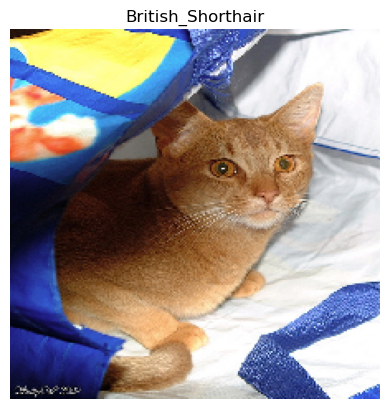

In [28]:
plt.imshow(img)
plt.title(le.inverse_transform([predicted_class])[0])
plt.axis("off")
plt.show()

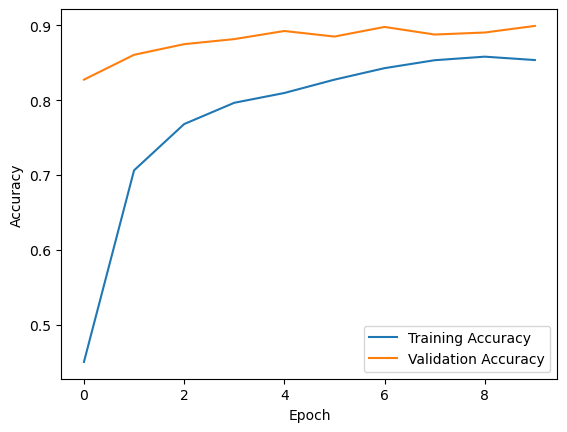

In [29]:
plt.plot(model_history.history["accuracy"], label="Training Accuracy")
plt.plot(model_history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()

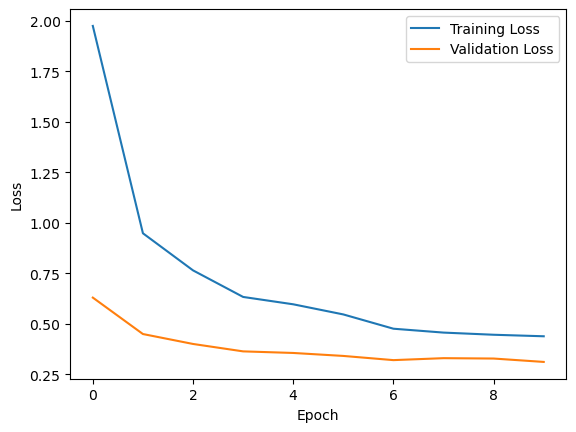

In [30]:
plt.plot(model_history.history["loss"], label="Training Loss")
plt.plot(model_history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

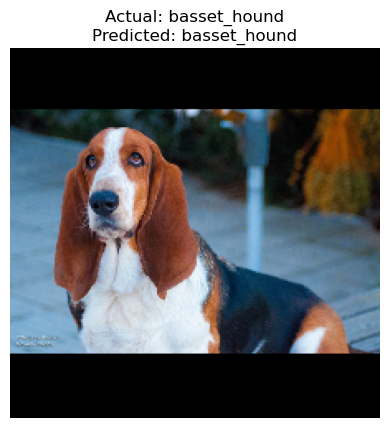

In [31]:
import random

index = random.randint(0, len(X_test)-1)

img = X_test[index]

prediction = model.predict(np.expand_dims(img, axis=0), verbose=0)

predicted = le.inverse_transform([np.argmax(prediction)])[0]
actual = le.inverse_transform([np.argmax(y_test[index])])[0]

plt.imshow(img.astype("uint8"))
plt.title(f"Actual: {actual}\nPredicted: {predicted}")
plt.axis("off")
plt.show()

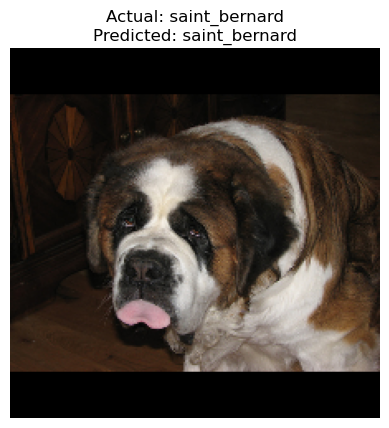

In [32]:
import random

index = random.randint(0, len(X_test)-1)

img = X_test[index]

prediction = model.predict(np.expand_dims(img, axis=0), verbose=0)

predicted = le.inverse_transform([np.argmax(prediction)])[0]
actual = le.inverse_transform([np.argmax(y_test[index])])[0]

plt.imshow(img.astype("uint8"))
plt.title(f"Actual: {actual}\nPredicted: {predicted}")
plt.axis("off")
plt.show()

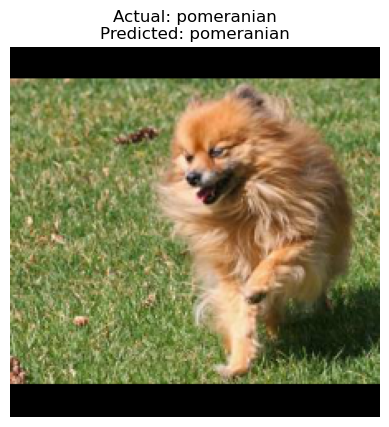

In [33]:
import random

index = random.randint(0, len(X_test)-1)

img = X_test[index]

prediction = model.predict(np.expand_dims(img, axis=0), verbose=0)

predicted = le.inverse_transform([np.argmax(prediction)])[0]
actual = le.inverse_transform([np.argmax(y_test[index])])[0]

plt.imshow(img.astype("uint8"))
plt.title(f"Actual: {actual}\nPredicted: {predicted}")
plt.axis("off")
plt.show()

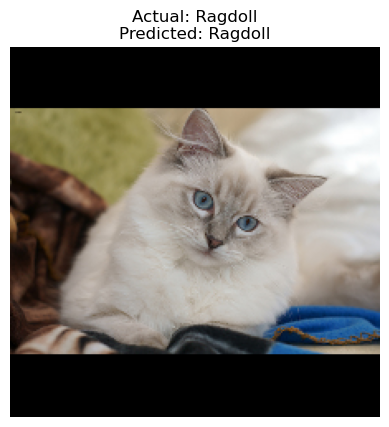

In [34]:
import random

index = random.randint(0, len(X_test)-1)

img = X_test[index]

prediction = model.predict(np.expand_dims(img, axis=0), verbose=0)

predicted = le.inverse_transform([np.argmax(prediction)])[0]
actual = le.inverse_transform([np.argmax(y_test[index])])[0]

plt.imshow(img.astype("uint8"))
plt.title(f"Actual: {actual}\nPredicted: {predicted}")
plt.axis("off")
plt.show()

Enter image number:  245


american_bulldog_140.jpg


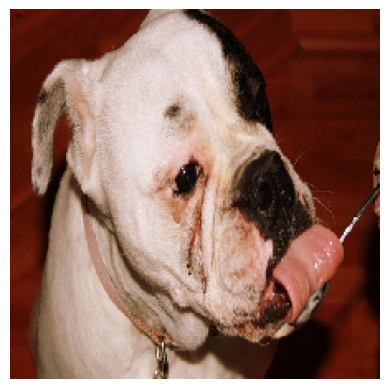

Prediction: american_bulldog


In [35]:
num = int(input("Enter image number: "))

img_name = images_names[num]

print(img_name)
img = load_img(os.path.join("images", img_name), target_size=(224,224))

plt.imshow(img)
plt.axis("off")
plt.show()

img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = pp_i(img_array)

prediction = model.predict(img_array, verbose=0)

predicted = le.inverse_transform([np.argmax(prediction)])[0]

print("Prediction:", predicted)

Enter image number:  13


Abyssinian_110.jpg


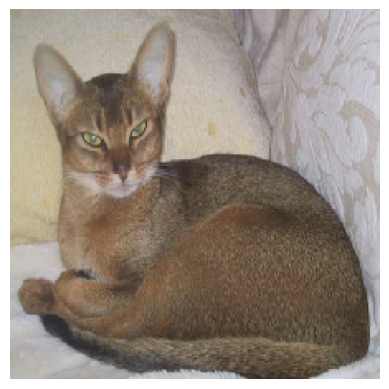

Prediction: Abyssinian


In [36]:
num = int(input("Enter image number: "))

img_name = images_names[num]

print(img_name)
img = load_img(os.path.join("images", img_name), target_size=(224,224))

plt.imshow(img)
plt.axis("off")
plt.show()

img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = pp_i(img_array)

prediction = model.predict(img_array, verbose=0)

predicted = le.inverse_transform([np.argmax(prediction)])[0]

print("Prediction:", predicted)

Enter image number:  1546


Bombay_5.jpg


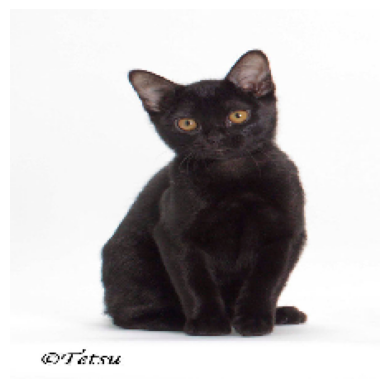

Prediction: Bombay


In [37]:
num = int(input("Enter image number: "))

img_name = images_names[num]

print(img_name)
img = load_img(os.path.join("images", img_name), target_size=(224,224))

plt.imshow(img)
plt.axis("off")
plt.show()

img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = pp_i(img_array)

prediction = model.predict(img_array, verbose=0)

predicted = le.inverse_transform([np.argmax(prediction)])[0]

print("Prediction:", predicted)


In [38]:
model.save("pet_classifier.keras")


In [ ]:
from tensorflow.keras.models import load_model

model = load_model("pet_classifier.keras")